# 11 · Hyperparameter tuning

[Guide](../README.md) | [Previous](10_Model_Comparison.ipynb) | [Next](12_Ensembling.ipynb)

## 1. What problem are we solving?

Can we improve the selected model by changing its settings?

## 2. Why does it matter?

More complex settings can help or overfit; the largest search score is not an independent evaluation.

## 3. Key concepts

| Term | Simple meaning |
|---|---|
| Hyperparameter / trial | A setting chosen before fitting / one attempted setting combination. |
| Grid / random search | Try all listed combinations / sample some combinations without learning from previous scores. |
| Bayesian optimization | Use earlier trial results to guide promising later trials while still exploring. |
| Optuna / TPE | Optuna manages trials; its TPE sampler models settings seen in better versus worse trials to guide later suggestions. It does not learn test answers. |
| Inner / outer split | Inner splits choose settings; outer held-out groups score the whole search procedure. |
| Search budget | The number of attempted settings. Eight trials on a small grid can repeat settings and do not prove global optimality. |
| Parameters vs hyperparameters | Weights/splits learned during fitting versus settings such as depth chosen before fitting. |
| Pipeline notation | `clone` copies unfitted settings; `step__setting` changes one pipeline setting. Earlier steps stay fixed during a comparison. |

## 4. Intuitive example

The actual grid below has depths `[4, 6]` and learning rates `[0.03, 0.10]`: four combinations. Grid search tries all four; random search samples three. Optuna starts with random trials, then uses earlier scores to favor promising choices. A good inner score earns a proposal, not an independent performance claim.

## 5. Methods to compare

| Strategy | How it searches | Trade-off |
|---|---|---|
| Starter settings | No search | Cheap; may not suit the dataset |
| Manual alternative | Try one understandable change | Transparent; depends on the guess |
| Grid search | Try all four listed combinations | Thorough on this tiny grid; cost grows quickly |
| Random search | Sample three listed combinations | Smaller budget; can miss a useful setting |
| Optuna/TPE | Use earlier trial scores to guide eight trials | Can adapt after startup; can repeat settings on a small grid |

Inner cross-validation chooses settings. Outer held-out groups score the complete search, including Optuna; do not report the best inner trial as independent performance.

## 6. What we retained from previous notebooks

| Earlier decision | Choice used here |
|---|---|
| Missing | Drop incomplete training rows |
| Scaling | Robust scaling |
| Encoding | One-hot |
| Features | All candidate groups |
| Selection | Drop suspected decoys + L1 |
| Reduction | No PCA |
| Outliers | Add a flag |
| Balancing | Original class counts |
| Model | CatBoost |

## 7. Setup

**Reusable setup — run this cell, then skip to the lesson.** You do not need to study all these lines now: they load the data and rebuild earlier steps so this notebook works on its own. Revisit the earlier lessons for explanations.

Change `DATA_DIR` for your runtime. The cell starts collapsed where the editor supports it; GitHub may show it expanded. `X` contains inputs; `y` contains known answers. Learned preparation stays inside training folds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from imblearn import FunctionSampler
from imblearn.pipeline import Pipeline
from catboost import CatBoostClassifier

def remove_incomplete_rows(X, y):
    keep = ~X.isna().any(axis=1)
    return X.loc[keep], y[keep]

def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

pipeline = Pipeline([
    ("missing_rows", FunctionSampler(func=remove_incomplete_rows, validate=False)),
    ("outlier_values", FunctionTransformer(add_outlier_flag)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("model", CatBoostClassifier(iterations=200, depth=5, learning_rate=0.05, loss_function="Logloss", random_seed=42, thread_count=2, verbose=False, allow_writing_files=False)),
])

# Each fold trains on two parts and predicts the third, unseen part.
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

def compare(models, X, y):
    rows = []
    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=["f1", "accuracy", "roc_auc"])
        rows.append([name, scores["test_f1"].mean(), scores["test_f1"].std(),
                     scores["test_accuracy"].mean(), scores["test_roc_auc"].mean()])
    columns = ["method", "F1", "F1 spread", "accuracy", "ROC-AUC"]
    return pd.DataFrame(rows, columns=columns).sort_values("F1", ascending=False)

Train: (20000, 20) Test: (6000, 19)


## 8. Experiments

Run the topic-specific steps below. Saved experimental outputs are retained from the earlier runs; regrouping setup does not create a new evaluation.

In [17]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
settings = {'model__depth': [4, 6], 'model__learning_rate': [0.03, 0.1]}
manual_settings = {'model__depth': 4}

In [18]:
models = {
    "Default settings": clone(pipeline),
    "Manual settings": clone(pipeline).set_params(**manual_settings),
    "Grid search": GridSearchCV(clone(pipeline), settings, scoring="f1", cv=cv),
    "Random search": RandomizedSearchCV(clone(pipeline), settings, n_iter=3, scoring="f1", cv=cv, random_state=42),
}

### Optuna: tell a trial what to try and what score to return
An **objective** is the function Optuna tries to improve. Here it returns training-only cross-validation F1.
`suggest_categorical` chooses from the same small lists used by grid/random search.
`direction="maximize"` asks for a larger score. The helper below returns the study and its best settings.

### Before the Optuna implementation

A toy trial might return F1 0.90 for depth 4 and 0.92 for depth 6. After startup trials, TPE uses the accumulated good/bad trial results to guide later proposals; it does not simply copy the single highest score. The `objective` below returns inner cross-validation F1. The later outer loop checks the complete tuning procedure on rows that trial selection did not use.

In [19]:
import optuna
from sklearn.model_selection import cross_val_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

def run_optuna(X_fit, y_fit):
    def objective(trial):
        parameters = {}
        for name, values in settings.items():
            parameters[name] = trial.suggest_categorical(name, values)
        candidate = clone(pipeline).set_params(**parameters)
        return cross_val_score(candidate, X_fit, y_fit, cv=cv, scoring="f1", error_score="raise").mean()
    sampler = optuna.samplers.TPESampler(seed=42, n_startup_trials=3)
    study = optuna.create_study(direction="maximize", sampler=sampler)
    study.optimize(objective, n_trials=8)
    return study

### Score the whole Optuna search on unseen training groups
For each outer group: search on the other groups, fit those settings there, then predict the hidden group.
The same pipeline keeps imputation, selection, and cleaning inside every fit.
The separate final validation set is not passed to the search.

In [20]:
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
trial_scores = []
for fit_rows, score_rows in cv.split(X, y):
    X_fit, y_fit = X.iloc[fit_rows], y.iloc[fit_rows]
    X_score, y_score = X.iloc[score_rows], y.iloc[score_rows]
    study = run_optuna(X_fit, y_fit)
    fitted = clone(pipeline).set_params(**study.best_params).fit(X_fit, y_fit)
    prediction = fitted.predict(X_score)
    probability = fitted.predict_proba(X_score)[:, 1]
    trial_scores.append([f1_score(y_score, prediction), accuracy_score(y_score, prediction),
                         roc_auc_score(y_score, probability)])
trial_scores = np.array(trial_scores)

,method,F1,F1 spread,accuracy,ROC-AUC
0,Random search,0.945,0.002,0.951,0.992
1,Grid search,0.945,0.002,0.951,0.992
4,Optuna search,0.945,0.002,0.951,0.992
2,Default settings,0.944,0.003,0.950,0.991
3,Manual settings,0.940,0.002,0.947,0.990


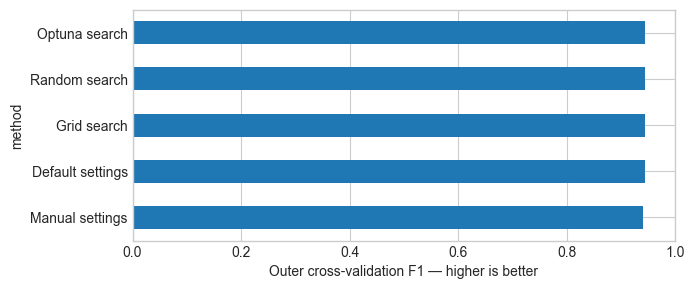

Continue with: Random search


In [21]:
results = compare(models, X, y)
optuna_row = pd.DataFrame([["Optuna search", trial_scores[:, 0].mean(), trial_scores[:, 0].std(),
                           trial_scores[:, 1].mean(), trial_scores[:, 2].mean()]], columns=results.columns)
results = pd.concat([results, optuna_row], ignore_index=True).sort_values("F1", ascending=False, kind="stable")
display(results.round(4))
results.set_index("method")["F1"].sort_values().plot.barh(figsize=(7, 3))
plt.xlabel("Outer cross-validation F1 — higher is better")
plt.xlim(0, 1)
plt.show()
print("Continue with:", results.iloc[0]["method"])

In [22]:
optuna_example = run_optuna(X, y)
selected_name = results.iloc[0]["method"]
chosen_parameters = {}
if selected_name == "Optuna search":
    chosen_parameters = optuna_example.best_params
else:
    selected = clone(models[selected_name]).fit(X, y)
    if selected_name in ["Grid search", "Random search"]:
        chosen_parameters = selected.best_params_
    elif selected_name == "Manual settings":
        chosen_parameters = manual_settings
print("Settings to continue:", chosen_parameters)

Settings to continue: {'model__learning_rate': 0.1, 'model__depth': 6}


### Example: inspect Optuna's attempts
Fit one study on the training part to inspect its proposals. The best trial's score is an inner search score,
not a new final-validation result. This illustration does not replace the outer comparison above.
`cummax()` keeps the best score seen so far. Eight trials on this tiny space may repeat combinations;
search budgets differ, so the comparison is educational, not an equal-budget benchmark.

,number,value,params_model__depth,params_model__learning_rate
0,0,0.942,6,0.03
1,1,0.946,4,0.10
2,2,0.946,6,0.10
3,3,0.946,6,0.10
4,4,0.946,6,0.10
5,5,0.931,4,0.03
6,6,0.946,6,0.10
7,7,0.946,4,0.10


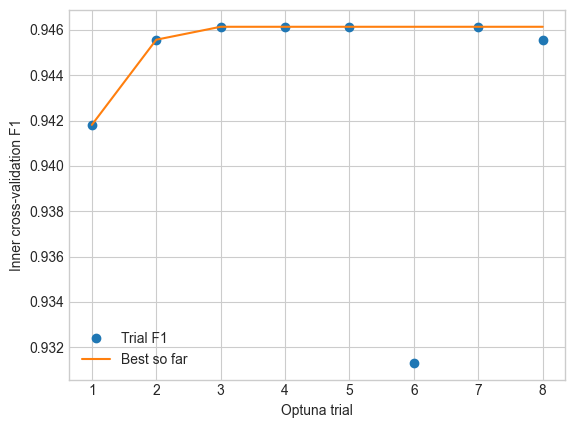

In [23]:
trials = optuna_example.trials_dataframe()
trial_columns = ["number", "value"] + [name for name in trials if name.startswith("params_")]
display(trials[trial_columns])
plt.plot(trials["number"] + 1, trials["value"], "o", label="Trial F1")
plt.plot(trials["number"] + 1, trials["value"].cummax(), label="Best so far")
plt.xlabel("Optuna trial")
plt.ylabel("Inner cross-validation F1")
plt.legend()
plt.show()

**Other alternatives:** successive halving gives more training resources to promising candidates.
**Pruning** stops weak trials early; it requires intermediate progress reports and is not enabled here.
`suggest_float` tries numerical values between limits; `suggest_int` tries whole numbers between limits.
Wider ranges need more trials. These extensions are useful later, not required in the final notebook.

Reference: [Optuna TPE sampler](https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html).

## 9. Results and decision

| Question | Answer |
|---|---|
| What did we compare? | Starter settings, a manual alternative, grid search, random search, and an eight-trial Optuna search, with outer cross-validation. |
| Which performed best? | Random search — outer CV F1 0.9450 (rounded saved result). |
| Why did we choose it? | The tested random search has the best outer score; carry only its selected settings, not a search into the final notebook. |
| What are its limitations? | Only four listed combinations and eight Optuna trials were explored. Scores remain selection evidence, not the final independent check. |
| What continues to the next notebook? | CatBoost depth 6, learning rate 0.1, 200 iterations; no search in the final notebook. |

## 10. Key takeaways and next step

- Search scores help choose settings; outer predictions check the search procedure.
- Optuna learns from earlier training-trial scores, not from test answers.

Next: [12 Ensembling](12_Ensembling.ipynb).